# ITC Hotels - Module 2: Food, Beverage & Banquet Performance Analytics
### Author: Goku | ITC Hotels Hospitality Analytics Project
**Focus:** Restaurant Outlets (*Bukhara*, *Dum Pukht*, *Peshawri*), Dining Covers, Dining Plans, Banquet Ballrooms, MICE Summits & Destination Weddings.

---
## 1. Executive Summary & Business Context
ITC Hotels is globally celebrated for its culinary legacy — brands like **Bukhara** and **Dum Pukht** are international benchmarks. Additionally, large-scale banquet spaces (e.g. *Rajputana Grand Ballroom*, *Chola Conclave*) generate massive high-margin corporate summit and luxury wedding revenue.

This module evaluates dining outlet productivity, Average Spend Per Cover (APC), and banquet capacity monetization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

df_fnb = pd.read_csv('itc_fnb_banquet_performance.csv')
print(f"Total Dining & Banquet Records: {len(df_fnb):,}")
df_fnb.head()

Total Dining & Banquet Records: 119,390


,booking_id,hotel_name,arrival_date,arrival_date_year,arrival_date_month,is_canceled,dining_plan,primary_restaurant_outlet,dining_covers,food_revenue_inr,beverage_revenue_inr,total_fnb_revenue_inr,banquet_hall_booked,banquet_event_type,banquet_attendees,banquet_revenue_inr,combined_fnb_banquet_rev_inr
0,ITC-2015-000001,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,0,Bed & Breakfast (Continental Buffet),Dum Pukht Awadhi,2,4026.18,1426.52,5452.70,NaN,NaN,0,0.0,5452.70
1,ITC-2015-000002,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,0,Bed & Breakfast (Continental Buffet),Avartana Southern Fine Dining,2,3500.04,1214.43,4714.47,NaN,NaN,0,0.0,4714.47
2,ITC-2015-000003,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,0,Bed & Breakfast (Continental Buffet),The Pavilion (24/7),1,1834.14,593.43,2427.57,NaN,NaN,0,0.0,2427.57
3,ITC-2015-000004,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,0,Bed & Breakfast (Continental Buffet),Peshawri Grill,1,2369.24,678.20,3047.44,Chola Conclave Hall,Corporate Annual Summit,231,1129777.4,1132824.84
4,ITC-2015-000005,ITC Grand Bharat & Mughal (Luxury Resort),2015-07-01,2015,July,0,Bed & Breakfast (Continental Buffet),Bukhara Tandoor,4,5810.29,1535.41,7345.70,NaN,NaN,0,0.0,7345.70


## 2. Core Culinary & Banqueting Scorecard

In [2]:
active_fnb = df_fnb[df_fnb['is_canceled'] == 0]
total_food_rev_cr = active_fnb['food_revenue_inr'].sum() / 1e7
total_bev_rev_cr = active_fnb['beverage_revenue_inr'].sum() / 1e7
total_banquet_rev_cr = active_fnb['banquet_revenue_inr'].sum() / 1e7
total_culinary_cr = active_fnb['combined_fnb_banquet_rev_inr'].sum() / 1e7
total_covers = active_fnb['dining_covers'].sum()
avg_cover_spend = (active_fnb['total_fnb_revenue_inr'].sum() / total_covers) if total_covers > 0 else 0

print("="*60)
print("ITC FOOD, BEVERAGE & BANQUET EXECUTIVE SCORECARD")
print("="*60)
print(f"Total Dining Covers Served : {total_covers:,}")
print(f"Food Revenue               : ₹ {total_food_rev_cr:,.2f} Crores")
print(f"Beverage Revenue           : ₹ {total_bev_rev_cr:,.2f} Crores")
print(f"Banquet & Events Revenue   : ₹ {total_banquet_rev_cr:,.2f} Crores")
print(f"Total F&B + Banquet Revenue: ₹ {total_culinary_cr:,.2f} Crores")
print(f"Average Spend Per Cover    : ₹ {avg_cover_spend:,.2f}")
print("="*60)

ITC FOOD, BEVERAGE & BANQUET EXECUTIVE SCORECARD
Total Dining Covers Served : 597,935
Food Revenue               : ₹ 116.78 Crores
Beverage Revenue           : ₹ 38.73 Crores
Banquet & Events Revenue   : ₹ 940.89 Crores
Total F&B + Banquet Revenue: ₹ 1,096.40 Crores
Average Spend Per Cover    : ₹ 2,600.78


## 3. Revenue Breakdown by Iconic ITC Restaurant Outlets

,primary_restaurant_outlet,total_covers,food_revenue_cr,beverage_revenue_cr,total_rev_cr,bev_share_pct
0,Bukhara Tandoor,150615,29.382477,9.724455,39.106932,24.866321
1,The Pavilion (24/7),118711,23.182020,7.667064,30.849084,24.853457
2,Dum Pukht Awadhi,118254,23.141187,7.666012,30.807199,24.883834
3,Peshawri Grill,90127,17.561571,5.848786,23.410356,24.983753
4,Royal Afghan & Bar,60826,11.901169,3.968983,15.870152,25.009105
5,Avartana Southern Fine Dining,59402,11.611485,3.854645,15.466130,24.923138


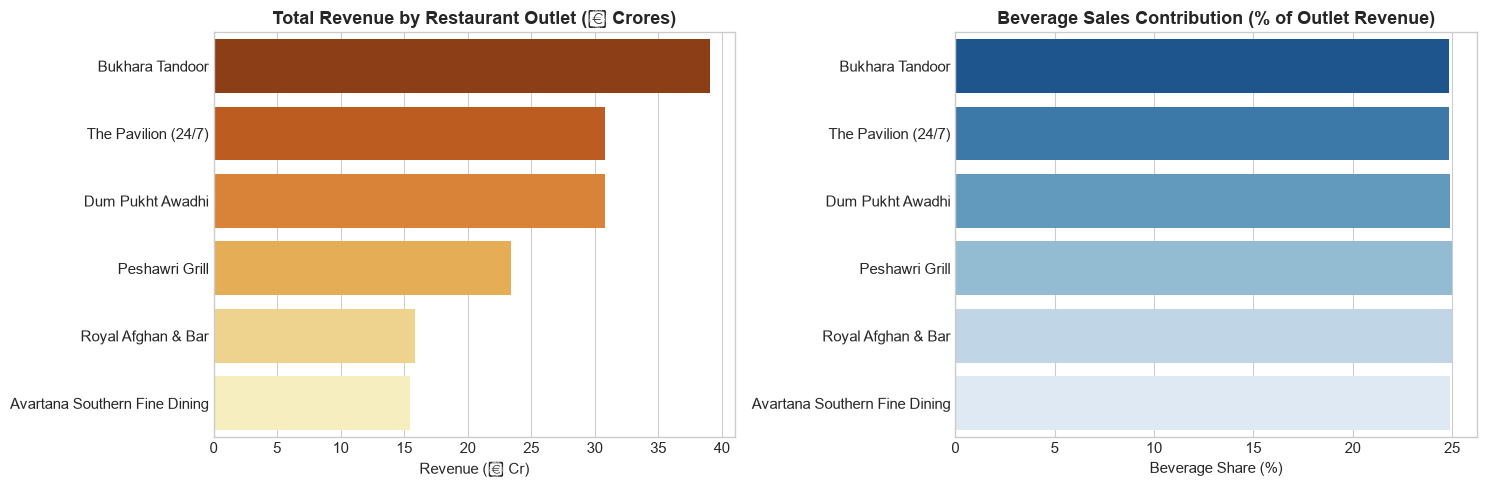

In [3]:
outlet_perf = active_fnb.groupby('primary_restaurant_outlet').agg(
    total_covers=('dining_covers', 'sum'),
    food_revenue_cr=('food_revenue_inr', lambda x: x.sum() / 1e7),
    beverage_revenue_cr=('beverage_revenue_inr', lambda x: x.sum() / 1e7),
    total_rev_cr=('total_fnb_revenue_inr', lambda x: x.sum() / 1e7)
).sort_values(by='total_rev_cr', ascending=False).reset_index()

outlet_perf['bev_share_pct'] = (outlet_perf['beverage_revenue_cr'] / outlet_perf['total_rev_cr']) * 100
display(outlet_perf)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=outlet_perf, x='total_rev_cr', y='primary_restaurant_outlet', ax=axes[0], palette='YlOrBr_r')
axes[0].set_title('Total Revenue by Restaurant Outlet (₹ Crores)', fontweight='bold')
axes[0].set_xlabel('Revenue (₹ Cr)')
axes[0].set_ylabel('')

sns.barplot(data=outlet_perf, x='bev_share_pct', y='primary_restaurant_outlet', ax=axes[1], palette='Blues_r')
axes[1].set_title('Beverage Sales Contribution (% of Outlet Revenue)', fontweight='bold')
axes[1].set_xlabel('Beverage Share (%)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

## 4. Banquet & Grand Ballroom Monetization
Analysis of MICE conferences, summits, and wedding banquets.

,banquet_hall_booked,events_hosted,total_attendees,total_banquet_cr,avg_event_ticket
0,Rajputana Grand Ballroom,5319,760295,317.795018,597471.363290
1,Darbar State Hall,3827,555471,234.117626,611752.354377
2,Chola Conclave Hall,3853,553272,231.121644,599848.542870
3,Nalanda Executive Auditorium,5304,381377,157.857716,297620.127426


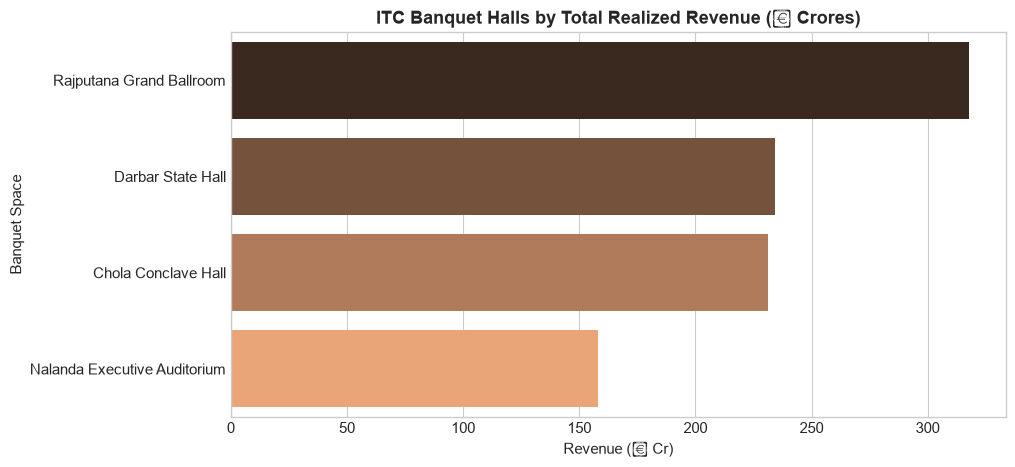

In [4]:
banquet_active = active_fnb[active_fnb['banquet_hall_booked'] != 'None']

banquet_summary = banquet_active.groupby('banquet_hall_booked').agg(
    events_hosted=('booking_id', 'count'),
    total_attendees=('banquet_attendees', 'sum'),
    total_banquet_cr=('banquet_revenue_inr', lambda x: x.sum() / 1e7),
    avg_event_ticket=('banquet_revenue_inr', 'mean')
).sort_values('total_banquet_cr', ascending=False).reset_index()

display(banquet_summary)

plt.figure(figsize=(10, 5))
sns.barplot(data=banquet_summary, x='total_banquet_cr', y='banquet_hall_booked', palette='copper')
plt.title('ITC Banquet Halls by Total Realized Revenue (₹ Crores)', fontweight='bold')
plt.xlabel('Revenue (₹ Cr)')
plt.ylabel('Banquet Space')
plt.show()

## 5. Event Types: Weddings vs Corporate Conclaves

,banquet_event_type,event_count,revenue_cr,avg_delegates
0,Corporate Annual Summit,6085,368.450897,144.729170
1,Medical / Tech Conference,4533,272.279946,143.650563
2,Luxury Royal Wedding Reception,3086,186.577773,144.328257
3,Government Delegation Gala,1557,92.958793,142.003211
4,Private Boardroom Meeting,3042,20.624594,17.118343


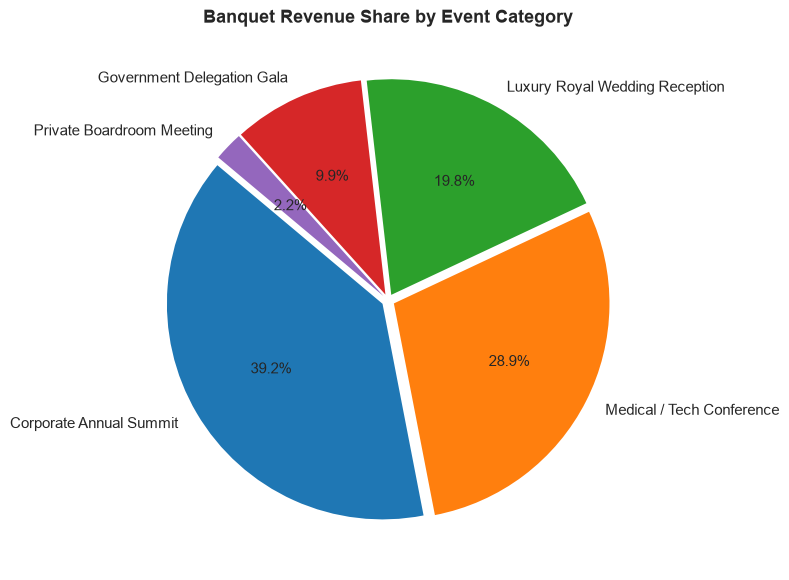

In [5]:
event_summary = banquet_active.groupby('banquet_event_type').agg(
    event_count=('booking_id', 'count'),
    revenue_cr=('banquet_revenue_inr', lambda x: x.sum() / 1e7),
    avg_delegates=('banquet_attendees', 'mean')
).sort_values('revenue_cr', ascending=False).reset_index()

display(event_summary)

plt.figure(figsize=(9, 7))
n_events = len(event_summary)
colors = sns.color_palette('tab10', n_events)
explode = [0.03] * n_events
plt.pie(event_summary['revenue_cr'], labels=event_summary['banquet_event_type'], autopct='%1.1f%%',
        colors=colors, startangle=140, explode=explode)
plt.title('Banquet Revenue Share by Event Category', fontweight='bold', fontsize=13)
plt.show()

## 6. Strategic Business Insights & Recommendations
1. **High-Margin Beverage Upselling:** Outlets like *Royal Afghan & Bar* and *Bukhara* maintain strong food volumes, but beverage sales are under 25% of the dining mix. Curated wine-pairing menus can elevate beverage share to 35%.
2. **Luxury Wedding Package Optimization:** Royal Wedding Receptions contribute the highest ticket size per event (~₹10 Lakhs - ₹15 Lakhs). Dedicated luxury bridal suites bundling will increase room-to-banquet conversion.
3. **Off-Peak Corporate Hall Utilization:** Weekday corporate summits in *Nalanda Auditorium* can be incentivized through discounted multi-day conference delegate passes.